# Size check in pixels: length, width, hole

Every step of `size_check.py` drawn on one image, then all images. The algorithm lives in `size_check.py` (module docstring has the method); this notebook only imports it and plots.

One tool for everything: a **caliper**, i.e. 1D edge detection. Sample along lines that cross the edge, walk from the clean side, and take the edge.

- **Length**: rows near the pill axis, walk from inside the pill out to each end. The rounded end only fades in brightness (a ~150 px ramp, no step), so the first edge uses the **colour distance** from the pill colour (Lab a,b, brightness ignored): it crosses halfway between the pill and the background level. Then each row's edge moves out to the **rim**, a thin light/dark line on the pill outline: the outermost RGB gradient peak at least `RATIO` x the strongest, from `RIM_IN` px inside to `RIM_OUT` px outside the colour edge. Where the background behind the end has the pill's colour (defect/12), the colour edge alone stops ~30 px inside the outline.
- **Width**: columns between the rounded ends, walk from inside the pill out to the top and bottom edge (the first step is the pill; the clamp ring further out is stronger).
- **Hole**: outer edge of the countersink (opening on the top face), measured the HALCON 2D-metrology way: 48 measure regions across the expected circle, profile averaged across each region, derivative of a Gaussian, the **last** dark->light edge going outward (the inner bore edge has the same polarity but lies further in), RANSAC circle fit that drops edge points landing on dirt or inside the hole. Circle, not ellipse: this edge stays round wherever the pill sits, and an ellipse stretches when one arc has no edges (defect/7, 8, 14). Diameter = 2 x circle radius.

Crop: `sku['matcher'].crop(image, pad=PAD)` (`template_matching.py`, same crop as train/infer, plus a `PAD` margin so the edges are inside); results drawn back on the raw image with `sku['matcher'].crop_matrix`.
Pass/fail in pixels: nominal = median of the good pills, tolerance = datasheet tolerance in % of nominal.

Sections: 1) every step on one image, 2) all images, 3) pass/fail, 4) results on the raw images.


In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter1d

from main import load_sku
from size_check import (A, DIMS, EDGE_OUT, GAP, MEASURE_LENGTH1, MEASURE_LENGTH2, MEASURE_SIGMA, MEASURE_THRESHOLD,
                        NUM_MEASURES, PAD, RATIO, RATIO_BOT, ROWS, T, calibrate, colour_dist, draw_overlay, geometry,
                        judge, measure, smooth_gray)

sku = load_sku('sku01')
g = geometry(sku)
TH, TW, MID, B, U, HOLE_CENTRES = (g[k] for k in ('TH', 'TW', 'MID', 'B', 'U', 'HOLE_CENTRES'))
HOLE_RADIUS = sku['hole_radius']

DATA = Path('data')
by_num = lambda p: (p.parent.name != 'good', int(p.stem))  # good first, then numeric
paths = {f'{p.parent.name}/{p.stem}': p for p in sorted(DATA.glob('raw/*/*.bmp'), key=by_num)}
print(len(paths), 'raw images')


26 raw images


## 1. Every step on one image

Change `STEP` to follow another image (e.g. `'good/1'`).

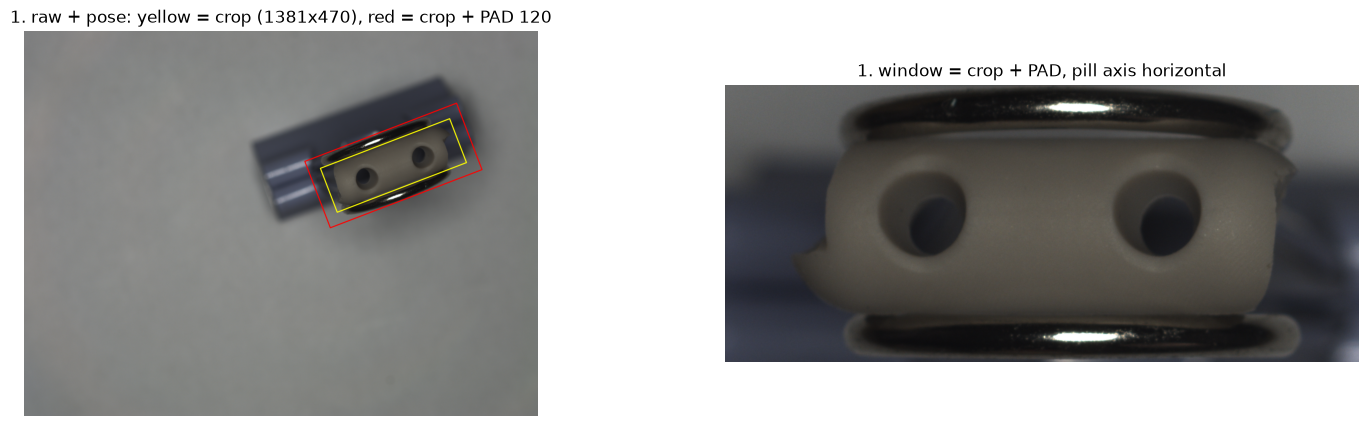

In [2]:
STEP = 'defect/8'
img = cv2.imread(str(paths[STEP]))
m = measure(img, sku)
w, (cx, cy), a = m['crop'], m['center'], m['angle']
g, cd = smooth_gray(w), colour_dist(w)

# step 1: the SKU's template matcher finds the pose (template matching) and cuts the crop with PAD margin
vis = img.copy()
for size, col in (((TW, TH), (0, 255, 255)), ((TW + 2 * PAD, TH + 2 * PAD), (0, 0, 255))):
    cv2.polylines(vis, [cv2.boxPoints(((float(cx), float(cy)), size, float(a))).astype(np.int32)], True, col, 10)
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].imshow(vis[..., ::-1]); ax[0].set_title(f'1. raw + pose: yellow = crop ({TW}x{TH}), red = crop + PAD {PAD}')
ax[1].imshow(w[..., ::-1]); ax[1].set_title('1. window = crop + PAD, pill axis horizontal')
for x in ax: x.axis('off')
plt.show()


### Length

Rows within ±`ROWS` of the axis; each row walks from column `A` to the left and from `B` to the right. Top plot: brightness (grey, no step at the ends) and colour distance (blue, a clean step) along the middle row. Dashed: the half level per side (halfway between the inside level and the background level); the edge is where the walk crosses it. 2a: yellow dots = colour edge per row, red dots = after moving out to the rim.

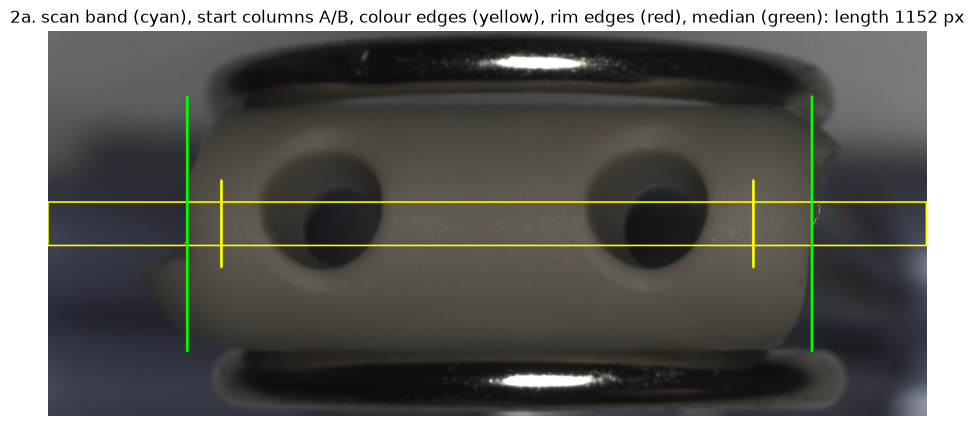

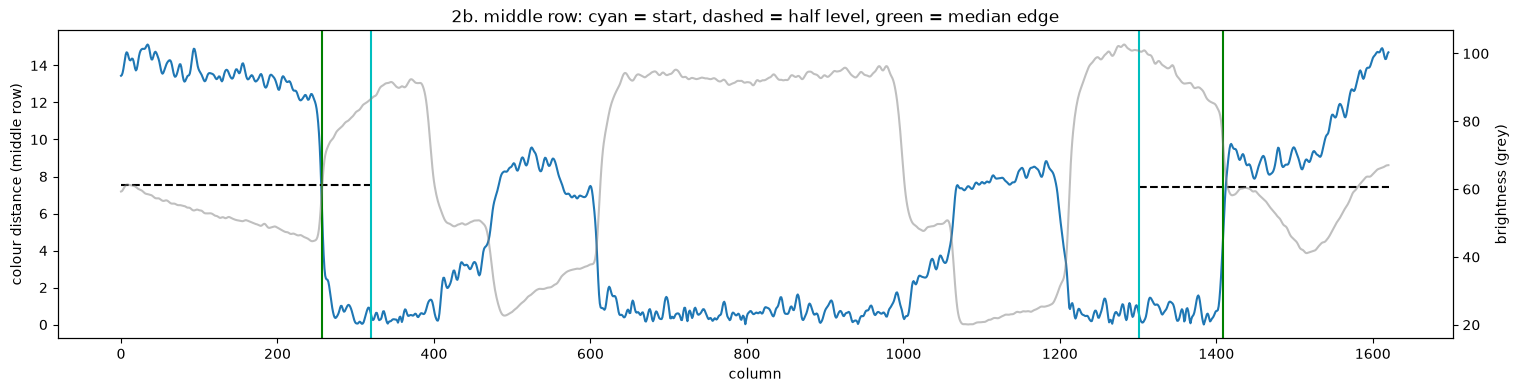

colour edge medians: left 255, right 1413
left edge: rows give 248..259, median 257
right edge: rows give 1405..1470, median 1409


In [3]:
fig, ax = plt.subplots(1, 1, figsize=(18, 5))
v = w[..., ::-1].copy()
cv2.rectangle(v, (0, MID - ROWS), (v.shape[1] - 1, MID + ROWS), (255, 255, 0), 2)
for x0 in (A, B):
    cv2.line(v, (x0, MID - ROWS - 40), (x0, MID + ROWS + 40), (255, 255, 0), 3)
for y, l0, r0, l, r in zip(range(MID - ROWS, MID + ROWS), m['lefts0'], m['rights0'], m['lefts'], m['rights']):
    v[y, int(l0)] = v[y, int(r0)] = (255, 255, 0)
    v[y, int(l)] = v[y, int(r)] = (255, 0, 0)
for x0 in (m['left'], m['right']):
    cv2.line(v, (int(x0), PAD), (int(x0), PAD + TH), (0, 255, 0), 3)
ax.imshow(v); ax.axis('off')
ax.set_title(f"2a. scan band (cyan), start columns A/B, colour edges (yellow), rim edges (red), median (green): length {m['length']:.0f} px")
plt.show()

prof = cd[MID]
fig, ax = plt.subplots(1, 1, figsize=(18, 4))
ax.plot(prof, label='colour distance'); ax.set_ylabel('colour distance (middle row)'); ax.set_xlabel('column')
axb = ax.twinx(); axb.plot(g[MID], color='gray', alpha=0.5); axb.set_ylabel('brightness (grey)')
for seg, x0, x1 in ((prof[A::-1], 0, A), (prof[B:], B, len(prof))):
    ax.hlines((np.median(seg[:50]) + np.median(seg[-50:])) / 2, x0, x1, colors='k', linestyles='--')
for x0 in (A, B): ax.axvline(x0, color='c')
for x0 in (m['left'], m['right']): ax.axvline(x0, color='g')
ax.set_title('2b. middle row: cyan = start, dashed = half level, green = median edge')
plt.show()
print(f"colour edge medians: left {np.median(m['lefts0']):.0f}, right {np.median(m['rights0']):.0f}")
print(f"left edge: rows give {m['lefts'].min()}..{m['lefts'].max()}, median {m['left']:.0f}")
print(f"right edge: rows give {m['rights'].min()}..{m['rights'].max()}, median {m['right']:.0f}")

### Width

Columns between `A` and `B`; each walks up from row `T` and down from row `U`. The first step is the pill edge; the clamp ring further out gives a stronger step, which is why it is the *first* step, not the strongest.

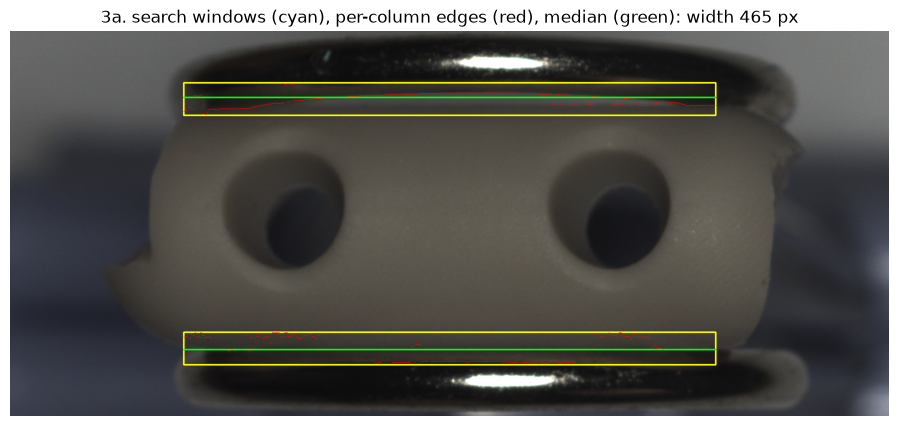

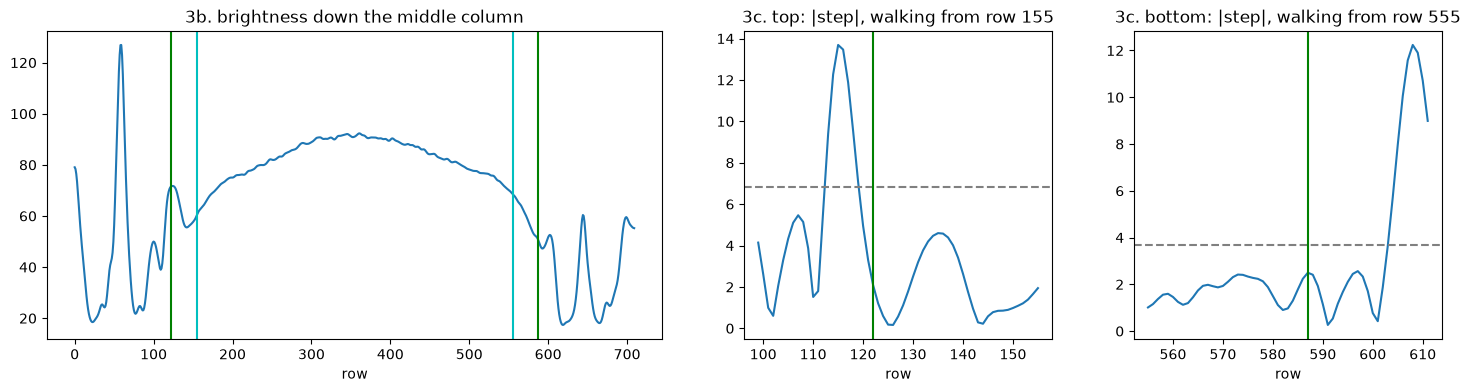

top: columns give 98..154, median 122
bottom: columns give 556..612, median 587


In [4]:
fig, ax = plt.subplots(1, 1, figsize=(18, 5))
v = w[..., ::-1].copy()
cv2.rectangle(v, (A, PAD - EDGE_OUT), (B, T), (255, 255, 0), 2)
cv2.rectangle(v, (A, U), (B, PAD + TH + EDGE_OUT), (255, 255, 0), 2)
xs = np.arange(A, B)
v[m['tops'].astype(int), xs] = (255, 0, 0)
v[m['bots'].astype(int), xs] = (255, 0, 0)
for y0 in (m['top'], m['bot']):
    cv2.line(v, (A, int(y0)), (B, int(y0)), (0, 255, 0), 2)
ax.imshow(v); ax.axis('off')
ax.set_title(f"3a. search windows (cyan), per-column edges (red), median (green): width {m['width']:.0f} px")
plt.show()

col = g[:, (A + B) // 2]
fig, ax = plt.subplots(1, 3, figsize=(18, 4), gridspec_kw=dict(width_ratios=[2, 1, 1]))
ax[0].plot(col); ax[0].set_title('3b. brightness down the middle column'); ax[0].set_xlabel('row')
for y0 in (T, U): ax[0].axvline(y0, color='c')
for y0 in (m['top'], m['bot']): ax[0].axvline(y0, color='g')
for x, (name, seg, ratio, y0, sign) in zip(ax[1:], (('top', col[T:PAD - EDGE_OUT:-1], RATIO, T, -1),
                                                   ('bottom', col[U:PAD + TH + EDGE_OUT], RATIO_BOT, U, 1))):
    d = np.abs(seg[GAP:] - seg[:-GAP])
    rr = y0 + sign * np.arange(len(d))
    x.plot(rr, d); x.axhline(ratio * d.max(), color='gray', ls='--'); x.axvline(m['top' if name == 'top' else 'bot'], color='g')
    x.set_title(f'3c. {name}: |step|, walking from row {y0}'); x.set_xlabel('row')
plt.show()
print(f"top: columns give {m['tops'].min()}..{m['tops'].max()}, median {m['top']:.0f}")
print(f"bottom: columns give {m['bots'].min()}..{m['bots'].max()}, median {m['bot']:.0f}")

### Holes

Per hole: the 48 measure regions across the expected circle (cyan), the edge found in each (red = used by the circle, yellow cross = rejected by RANSAC) and the fitted circle (green).
Right: the profile of the region at 0 deg (pointing right), its Gaussian derivative, the threshold and the **last** dark->light edge.

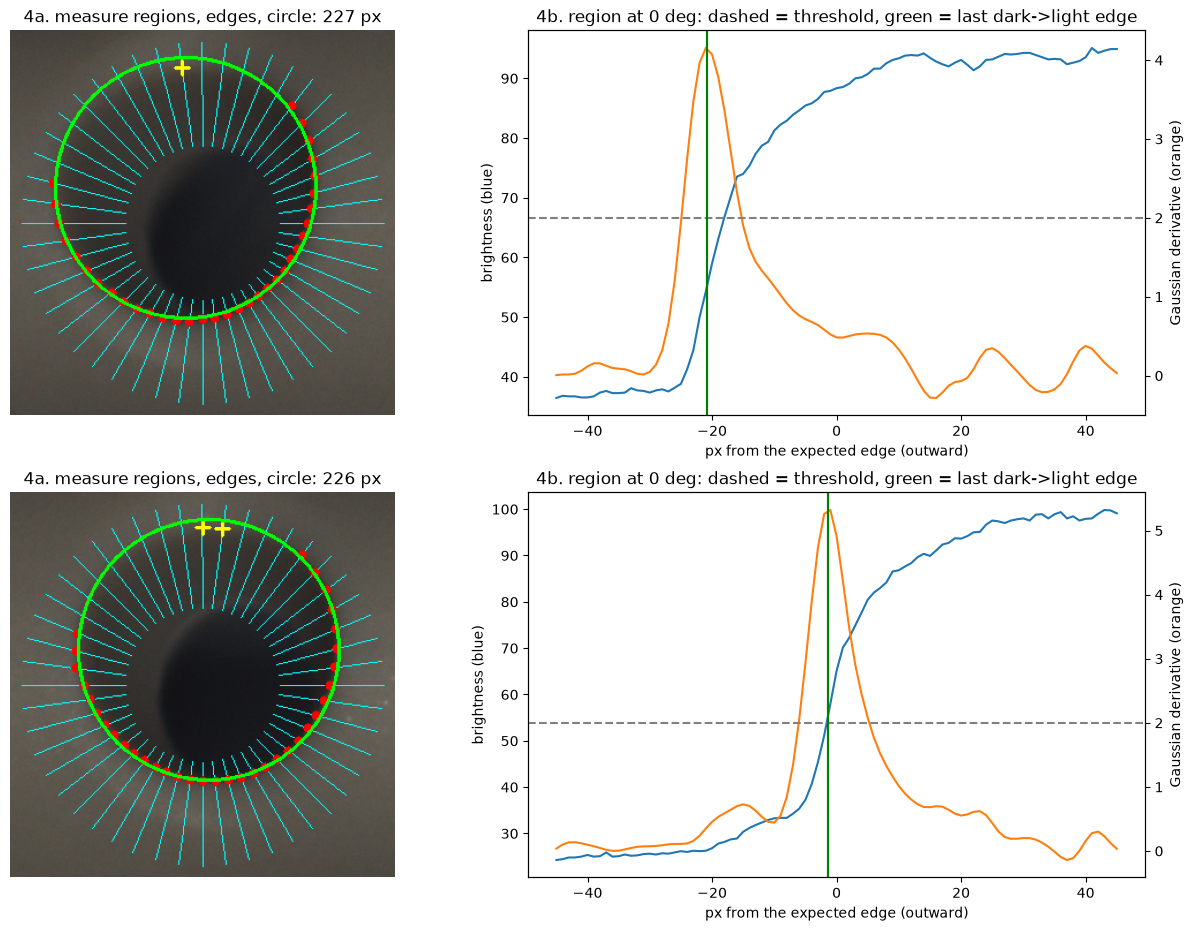

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(15, 11), gridspec_kw=dict(width_ratios=[1, 1.4]))
gray = cv2.cvtColor(w, cv2.COLOR_BGR2GRAY).astype(np.float32)
L1, L2 = MEASURE_LENGTH1, MEASURE_LENGTH2
for row, c, f in zip(ax, HOLE_CENTRES, m['holes']):
    half = HOLE_RADIUS + L1 + 10
    o = np.array(c) - half
    v = w[o[1]:o[1] + 2 * half, o[0]:o[0] + 2 * half, ::-1].copy()
    for phi in 2 * np.pi * np.arange(NUM_MEASURES) / NUM_MEASURES:
        n = np.array([np.cos(phi), np.sin(phi)])
        p0, p1 = (half + (HOLE_RADIUS - L1) * n).astype(int), (half + (HOLE_RADIUS + L1) * n).astype(int)
        cv2.line(v, tuple(p0), tuple(p1), (0, 255, 255), 1)
    if f:
        for (x, y), u in zip(f['points'], f['used']):
            if np.isnan(x):
                continue
            p = (int(x - o[0]), int(y - o[1]))
            cv2.circle(v, p, 4, (255, 0, 0), -1) if u else cv2.drawMarker(v, p, (255, 255, 0), cv2.MARKER_CROSS, 12, 2)
        cv2.circle(v, (int(round(f['center'][0] - o[0])), int(round(f['center'][1] - o[1]))), int(round(f['radius'])), (0, 255, 0), 2)
    row[0].imshow(v); row[0].axis('off')
    row[0].set_title(f"4a. measure regions, edges, circle: {2 * f['radius']:.0f} px" if f else '4a. no circle found')

    s = np.arange(-L1, L1 + 1)                               # region at 0 deg: a horizontal strip, no resampling
    x0 = c[0] + HOLE_RADIUS
    prof = gray[c[1] - L2:c[1] + L2 + 1, x0 - L1:x0 + L1 + 1].mean(0)
    d = gaussian_filter1d(prof, MEASURE_SIGMA, order=1)
    row[1].plot(s, prof)
    rb = row[1].twinx(); rb.plot(s, d, color='tab:orange')
    rb.axhline(MEASURE_THRESHOLD, color='gray', ls='--')
    if f and not np.isnan(f['points'][0, 0]):
        for x in (row[1], rb): x.axvline(f['points'][0, 0] - c[0] - HOLE_RADIUS, color='g')
    row[1].set_xlabel('px from the expected edge (outward)'); row[1].set_ylabel('brightness (blue)'); rb.set_ylabel('Gaussian derivative (orange)')
    row[1].set_title('4b. region at 0 deg: dashed = threshold, green = last dark->light edge')
plt.show()

## 2. All images

In [6]:
res = {}
for k, p in paths.items():
    r = res[k] = measure(cv2.imread(str(p)), sku)
    print(f"{k:10} length {r['length']:6.0f}  width {r['width']:4.0f}  holes {r['hole1']:4.0f} {r['hole2']:4.0f}")


good/1     length   1382  width  463  holes  225  226


good/2     length   1374  width  461  holes  224  225


good/3     length   1383  width  459  holes  223  224


good/4     length   1384  width  461  holes  223  225


good/5     length   1378  width  457  holes  223  223


good/6     length   1377  width  469  holes  227  227


... (16 outputs left out)

defect/11  length   1388  width  469  holes  227  227


defect/12  length   1380  width  453  holes  226  226


defect/13  length   1386  width  460  holes  228  227


defect/14  length   1157  width  446  holes  226  225


## 3. Pass / fail

The standard box is anchored on the midpoint of the two holes (they do not move when an end is cut, the template match does), so a short end shows how many px it is missing.

In [7]:
cal = calibrate([r for k, r in res.items() if k.startswith('good')], sku['spec_mm'])
for d in ('length', 'width', 'hole1'):
    print(f"{d:6}: nominal {cal['nominal'][d]:6.1f} px +- {cal['limit'][d]:4.1f} px")
print()
for k, r in res.items():
    judge(r, cal)
    dev = '  '.join(f"{d} {r[d] - cal['nominal'][d]:+6.1f}" for d in DIMS)
    print(f"{k:10} {dev}   left {r['left'] - r['L0']:+5.0f} right {r['R0'] - r['right']:+5.0f}   {'FAIL ' + ','.join(r['bad']) if r['bad'] else 'ok'}")


length: nominal 1378.5 px +- 18.6 px
width : nominal  463.0 px +- 13.9 px
hole1 : nominal  224.8 px +- 11.2 px

good/1     length   +3.5  width   +0.0  hole1   +0.2  hole2   +0.9   left    -2 right    +1   ok
good/2     length   -4.5  width   -2.0  hole1   -0.7  hole2   -0.3   left   +11 right    -4   ok
good/3     length   +4.5  width   -4.0  hole1   -1.7  hole2   -0.7   left   -22 right   +20   ok
good/4     length   +5.5  width   -2.0  hole1   -1.5  hole2   -0.3   left    -2 right    -1   ok
good/5     length   -0.5  width   -6.0  hole1   -1.9  hole2   -1.9   left    +2 right    +1   ok
good/6     length   -1.5  width   +6.0  hole1   +2.6  hole2   +2.2   left   +16 right   -12   ok
good/7     length   -9.5  width   +8.0  hole1   +1.1  hole2   +1.5   left   +29 right   -17   ok
good/8     length   -2.5  width   +8.0  hole1   +2.5  hole2   +2.5   left   +11 right    -6   ok
good/9     length   +3.5  width   -1.0  hole1   -0.9  hole2   -0.3   left    -6 right    +5   ok
good/10    leng

## 4. Results on the raw images

Yellow: standard box. Green/red: measured. A failing end gets a red line from the pill end to the standard end with the gap in px.

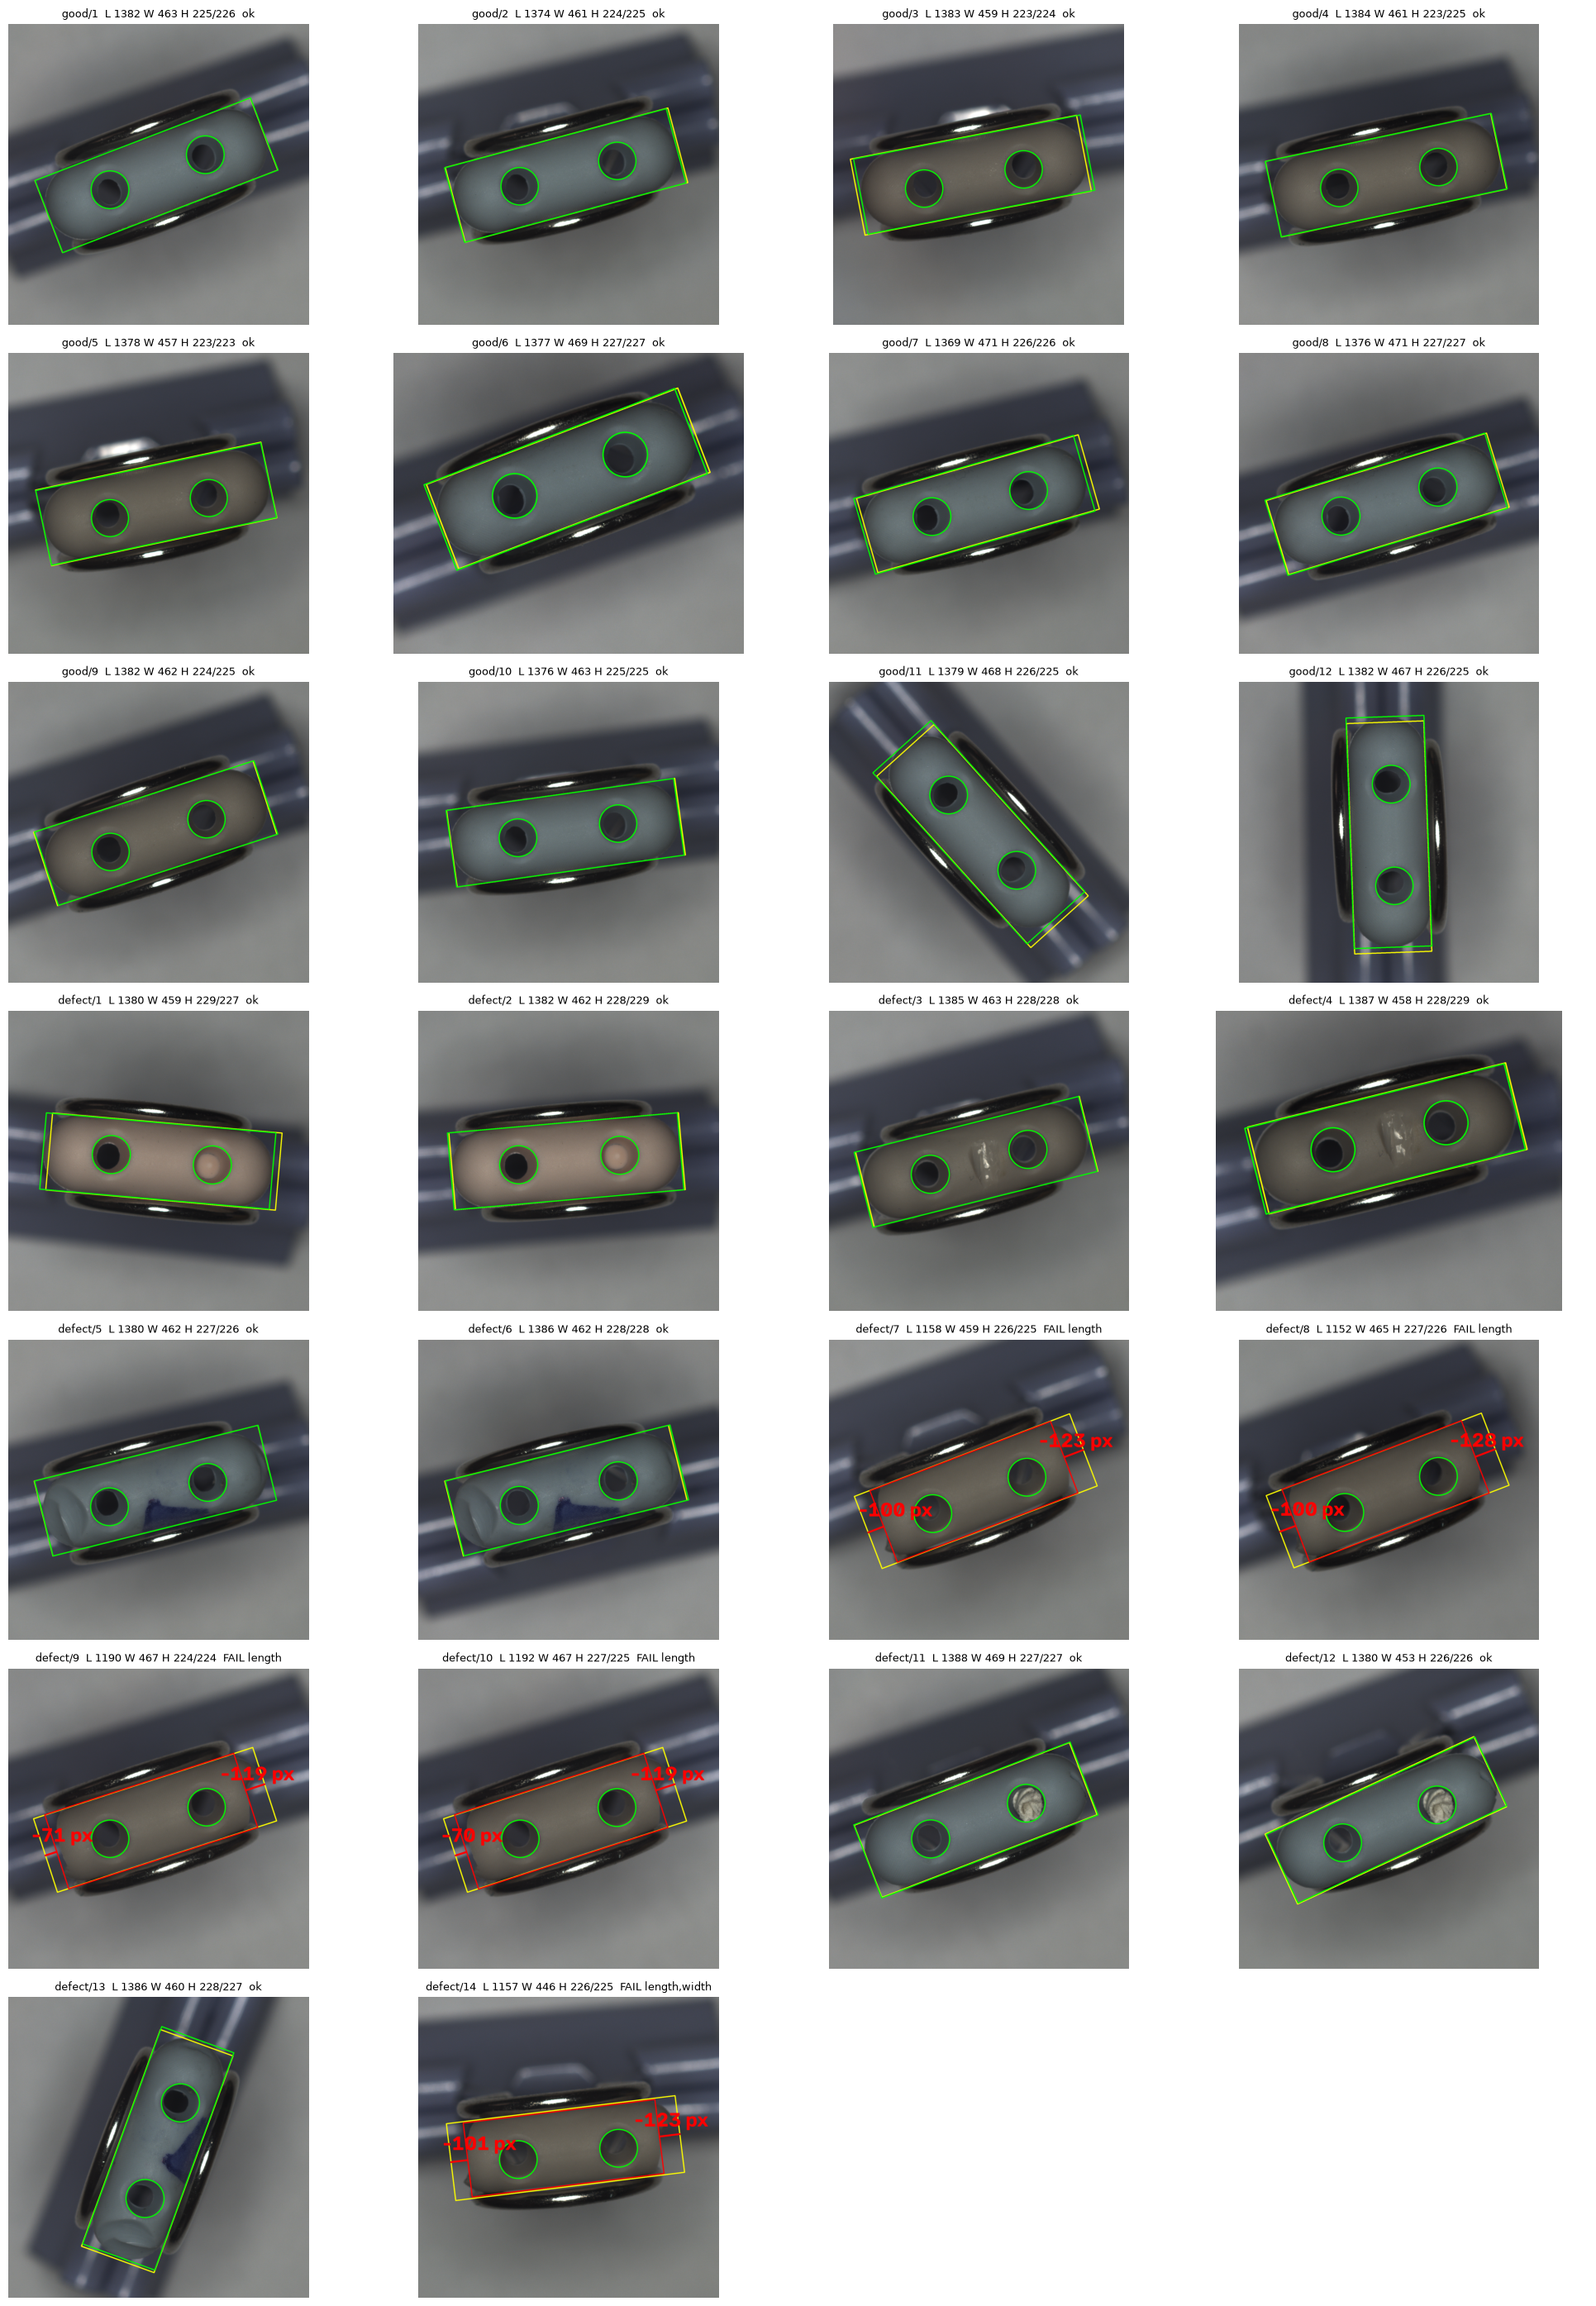

In [ ]:
cols = 4
fig, ax = plt.subplots(-(-len(res) // cols), cols, figsize=(cols * 5, -(-len(res) // cols) * 4))
for x in ax.flat:
    x.axis('off')
for x, (k, r) in zip(ax.flat, res.items()):
    x.imshow(draw_overlay(cv2.imread(str(paths[k])), r, cal)[..., ::-1])
    x.set_title(f"{k}  L {r['length']:.0f} W {r['width']:.0f} H {r['hole1']:.0f}/{r['hole2']:.0f}  {'FAIL ' + ','.join(r['bad']) if r['bad'] else 'ok'}", fontsize=9)
plt.tight_layout()
plt.savefig('outputs/size_check.png', dpi=70)